# Retail Sales & Demand Forecasting: walkthrough

Forecast daily unit sales for 500 store-item series (10 stores x 50 items) for the next 90 days, then turn the
forecast into an inventory plan. This notebook tells the story in order and **calls the pipeline modules in
`forecast/`**, so every number here comes from the same code the scripts and the dashboard use.

| Part | Question | Pipeline module |
|---|---|---|
| 1 | What does the data look like? | `forecast.data`, `forecast.prepare`, `forecast.wide` |
| 2 | What patterns matter? | plain pandas on the prepared table |
| 3 | How do we validate? | `forecast.splits` |
| 4 | What do simple baselines score? | `forecast.baselines`, `forecast.backtest` |
| 5 | How does the final model compare? | `forecast.dashboard_data` (reads the saved summaries) |
| 6 | What does a forecast look like? | `forecast.dashboard_data` |
| 7 | Where does the model err? | `forecast.dashboard_data` |
| 8 | What does it save in inventory? | `forecast.business` results |

Parts 1 to 4 need the Kaggle files in `data/raw/`. Parts 5 to 8 read the `dashboard_data/` bundle, which is
committed to the repo, so they run on a fresh clone.

In [1]:
import json
import logging
import os
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The notebook lives in notebooks/; run everything from the project root so relative paths in config work.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

from forecast.backtest import run_backtest
from forecast.baselines import build_baselines
from forecast.config import ForecastConfig
from forecast.data import load_raw
from forecast.logging_utils import configure_logging
from forecast.prepare import build_prepared_frame
from forecast.splits import make_validation_windows
from forecast.wide import to_wide

configure_logging("WARNING")
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})

cfg = ForecastConfig()
HAS_RAW = cfg.paths.train_csv.is_file() and cfg.paths.test_csv.is_file() and cfg.paths.sample_submission_csv.is_file()
BUNDLE_DIR = ROOT / "dashboard_data"
HAS_BUNDLE = (BUNDLE_DIR / "summaries.json").is_file()
print(f"project root: {ROOT}\nraw data found: {HAS_RAW}\ndashboard bundle found: {HAS_BUNDLE}")

project root: C:\Projects\retail-demand-forecasting
raw data found: True
dashboard bundle found: True


## 1. Data

The Kaggle file has one row per store, item and day from 2013-01-01 to 2017-12-31. `build_prepared_frame`
validates the columns, types and ranges, completes the store-item-day grid and adds calendar features. `to_wide`
reshapes it into a series x day matrix, which lets every baseline be a few numpy operations over all 500 series.

In [2]:
if HAS_RAW:
    raw = load_raw(cfg.paths)
    prepared, quality = build_prepared_frame(raw, cfg)
    wide = to_wide(prepared, cfg)
    print(f"series: {wide.n_series}, days: {wide.n_days}, {wide.dates[0].date()} to {wide.dates[-1].date()}")
    print(f"total units sold: {wide.values.sum():,.0f}")
    display(prepared.head())
else:
    print("data/raw/ is empty: download the Kaggle files to run parts 1 to 4.")

series: 500, days: 1826, 2013-01-01 to 2017-12-31
total units sold: 47,704,512


,store,item,date,sales,id,is_test,is_missing_day,dayofweek,day,month,year,quarter,dayofyear,weekofyear,is_weekend,is_month_start,is_month_end,t
0,1,1,2013-01-01,13.0,<NA>,False,False,1,1,1,2013,1,1,1,0,1,0,0
1,1,1,2013-01-02,11.0,<NA>,False,False,2,2,1,2013,1,2,1,0,0,0,1
2,1,1,2013-01-03,14.0,<NA>,False,False,3,3,1,2013,1,3,1,0,0,0,2
3,1,1,2013-01-04,13.0,<NA>,False,False,4,4,1,2013,1,4,1,0,0,0,3
4,1,1,2013-01-05,10.0,<NA>,False,False,5,5,1,2013,1,5,1,1,0,0,4


## 2. Patterns that drive the model

Every modelling choice follows from four findings in the exploratory analysis (Step 3), reproduced here from the
prepared data.

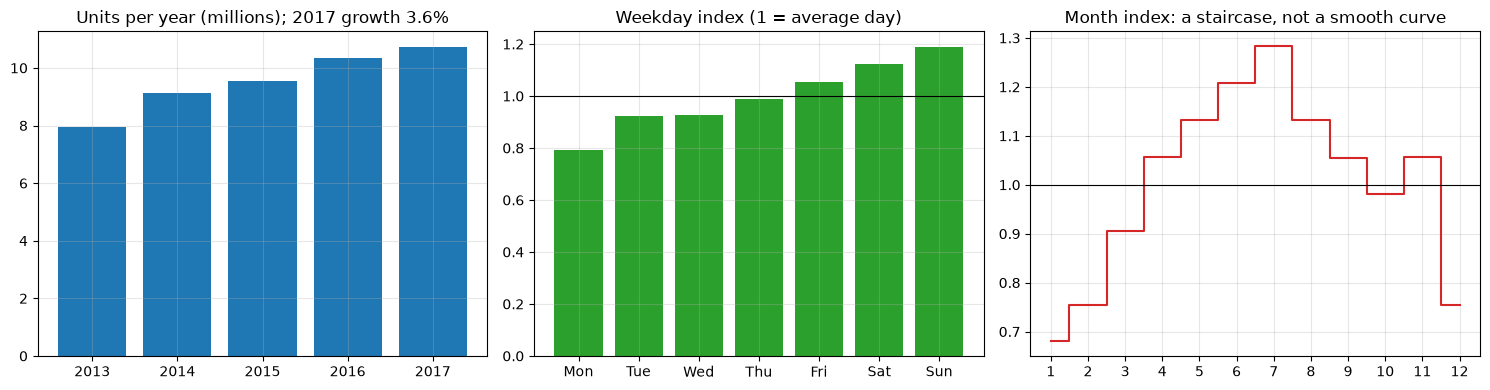

In [3]:
if HAS_RAW:
    total = pd.Series(wide.values.sum(axis=0), index=wide.dates)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    yearly = total.groupby(total.index.year).sum()
    axes[0].bar(yearly.index.astype(str), yearly.values / 1e6, color="tab:blue")
    axes[0].set_title(f"Units per year (millions); 2017 growth {100 * (yearly.iloc[-1] / yearly.iloc[-2] - 1):.1f}%")

    weekday = total.groupby(total.index.day_of_week).mean()
    axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday / weekday.mean(), color="tab:green")
    axes[1].axhline(1, color="black", linewidth=0.8)
    axes[1].set_title("Weekday index (1 = average day)")

    month = total.groupby(total.index.month).mean()
    axes[2].step(range(1, 13), month / month.mean(), where="mid", color="tab:red")
    axes[2].axhline(1, color="black", linewidth=0.8)
    axes[2].set_xticks(range(1, 13))
    axes[2].set_title("Month index: a staircase, not a smooth curve")
    plt.tight_layout()
    plt.show()

- **A weekly cycle** with Monday the low and Sunday the high, a swing of about 50%.
- **A yearly staircase.** The level is flat inside a month and steps at each month boundary, so month is used as an
  explicit feature. Smooth yearly curves (Fourier terms, Prophet's default) blur these steps.
- **One shared shape.** Every series follows nearly the same weekday and month profile, which supports one global model.
- **No holiday effect and no intermittent demand**, so no holiday features and no intermittent-demand methods.

2017 growth across the 500 series, percent:
count    500.00
mean       3.82
std        1.10
min       -0.35
5%         2.06
50%        3.84
95%        5.51
max        9.30


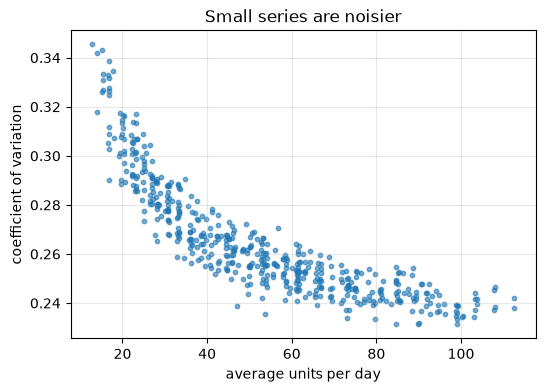

In [4]:
if HAS_RAW:
    # Same-weekday growth between consecutive years for each series, to show one shared trend fits all of them.
    last_year = wide.values[:, -364:].sum(axis=1)
    year_before = wide.values[:, -728:-364].sum(axis=1)
    growth = 100 * (last_year / year_before - 1)
    print("2017 growth across the 500 series, percent:")
    print(pd.Series(growth).describe(percentiles=[0.05, 0.5, 0.95]).round(2).to_string())

    # Poisson-like noise: relative error shrinks as volume grows, so big series are easier to forecast.
    volume = wide.values.mean(axis=1)
    cv = wide.values[:, -364:].std(axis=1) / wide.values[:, -364:].mean(axis=1)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(volume, cv, s=10, alpha=0.6)
    ax.set_xlabel("average units per day")
    ax.set_ylabel("coefficient of variation")
    ax.set_title("Small series are noisier")
    plt.show()

## 3. Validation

Only time-based validation is used. Four expanding windows of 90 days each end on 2017-03-31, 2017-06-30,
2017-09-30 and 2017-12-31. The first has the same season as the Kaggle test period (January to March), and the model
only ever sees data before each window starts.

In [5]:
if HAS_RAW:
    windows = make_validation_windows(wide.dates[0], wide.dates[-1], cfg)
    display(pd.DataFrame([w.as_dict() for w in windows]))

,train_end,valid_start,valid_end
0,2016-12-31,2017-01-01,2017-03-31
1,2017-04-01,2017-04-02,2017-06-30
2,2017-07-02,2017-07-03,2017-09-30
3,2017-10-02,2017-10-03,2017-12-31


## 4. Baselines

The benchmark to beat is `seasonal_naive_364`: the same weekday one year earlier (364 days, not 365, so the weekday
lines up). The pipeline's `run_backtest` scores every baseline on every window with WAPE, the primary metric
(total absolute error divided by total units sold).

window_end,2017-03-31,2017-06-30,2017-09-30,2017-12-31,mean_wape,vs_benchmark_pct
baseline,,,,,,
month_weekday_profile_multi_year,12.56,10.21,10.02,11.23,11.01,25.3
month_weekday_profile,12.91,10.89,10.77,12.01,11.65,21.0
month_weekday_profile_growth,13.66,10.72,10.57,11.81,11.69,20.7
seasonal_naive_364,16.43,13.66,13.61,15.29,14.74,0.0
seasonal_naive_364_growth,17.66,13.70,13.57,15.27,15.05,-2.1
seasonal_moving_average,16.94,20.76,13.42,19.72,17.71,-20.1
seasonal_naive_7,19.57,21.07,16.32,21.32,19.57,-32.8
moving_average,18.93,21.90,16.04,21.51,19.59,-32.9
naive,22.21,18.07,34.63,24.29,24.80,-68.2


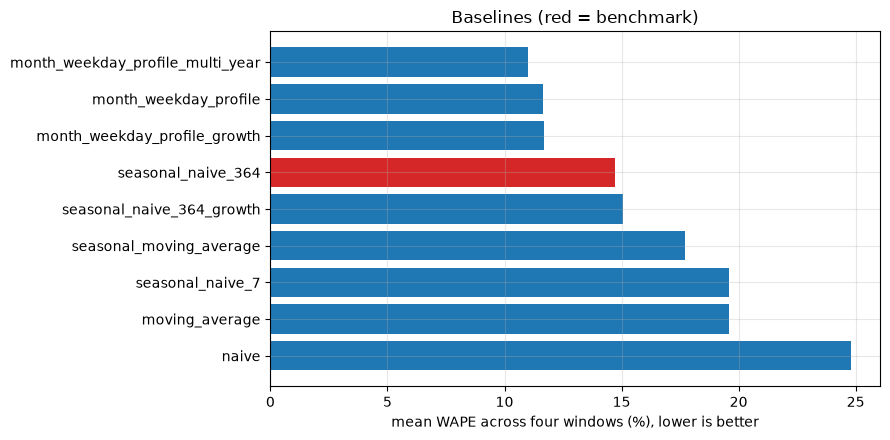

In [6]:
if HAS_RAW:
    baselines = build_baselines(cfg.baselines)
    scores = run_backtest(wide, windows, baselines, cfg)
    overall = scores[scores["scope"] == "all"]
    table = overall.pivot(index="baseline", columns="window_end", values="wape")
    table["mean_wape"] = table.mean(axis=1)
    table = table.sort_values("mean_wape").round(2)
    benchmark = table.loc[cfg.benchmark, "mean_wape"]
    table["vs_benchmark_pct"] = (100 * (1 - table["mean_wape"] / benchmark)).round(1)
    display(table)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ordered = table["mean_wape"].sort_values(ascending=False)
    ax.barh(ordered.index, ordered.values, color=["tab:red" if n == cfg.benchmark else "tab:blue" for n in ordered.index])
    ax.set_xlabel("mean WAPE across four windows (%), lower is better")
    ax.set_title("Baselines (red = benchmark)")
    plt.tight_layout()
    plt.show()

The best baseline averages the same month and weekday over the last two years and scales by recent growth. It is
already about 25% better than the benchmark, because it knows about the month staircase.

## 5. Model comparison

The rest of the models were run by the pipeline scripts (`run_statistical`, `run_gbm`, `run_tuning`). Their saved
summaries are bundled with the dashboard, so the comparison below is read, not recomputed.

In [7]:
from forecast.dashboard_data import (
    at_risk_table, backtest_errors, load_bundle, model_comparison, plot_error_bars,
    plot_series_forecast, series_slice)

# forecast.dashboard_data switches matplotlib to the headless Agg backend when it is imported, so turn the
# notebook's inline backend back on, otherwise the charts below are drawn but never shown.
%matplotlib inline

if HAS_BUNDLE:
    bundle = load_bundle(BUNDLE_DIR)
    comparison = model_comparison(bundle.summaries)
    display(comparison)
    selected = comparison.loc[comparison["selected"], "model"].iloc[0]
    print(f"selected model: {selected}")
else:
    print("dashboard_data/ not found: run `python -m forecast.dashboard_data` first.")

,model,family,mean_wape,vs_benchmark_pct,selected
0,gbm_tuned_calibrated,gradient boosting,10.355,29.8,True
1,gbm_tuned_calibrated_blend,gradient boosting,10.355,29.8,False
2,gbm_tuned_blend,gradient boosting,10.430,29.3,False
3,gbm_tuned,gradient boosting,10.438,29.2,False
4,gbm_default,gradient boosting,10.455,29.1,False
5,month_weekday_profile_multi_year,baseline,11.005,25.4,False
6,month_weekday_profile,baseline,11.647,21.0,False
7,month_weekday_profile_growth,baseline,11.690,20.7,False
8,seasonal_naive_364,baseline,14.744,0.0,False
9,seasonal_naive_364_growth,baseline,15.051,-2.1,False


selected model: gbm_tuned_calibrated


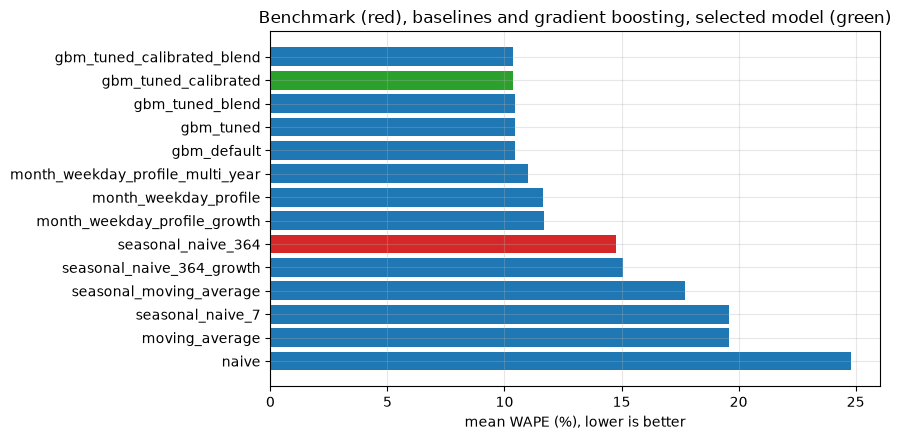

In [8]:
if HAS_BUNDLE:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ordered = comparison.sort_values("mean_wape", ascending=False)
    colors = ["tab:green" if s else ("tab:red" if m == "seasonal_naive_364" else "tab:blue")
              for m, s in zip(ordered["model"], ordered["selected"])]
    ax.barh(ordered["model"], ordered["mean_wape"], color=colors)
    ax.set_xlabel("mean WAPE (%), lower is better")
    ax.set_title("Benchmark (red), baselines and gradient boosting, selected model (green)")
    plt.tight_layout()
    plt.show()

**Reading the table.** The gradient-boosting model (LightGBM, one global model for all series, target = sales divided
by the series' trailing-year average, calibrated for bias) beats the best baseline by about 0.6 WAPE points and the
benchmark by about 30%. Statistical models (Holt-Winters, SARIMA, Prophet) were tested on a 10-series sample and did
not beat the month-weekday profile, because they smooth over the monthly steps. Tuning and calibration together
added only about 0.1 points: the data is close to its noise floor, so a bigger model would buy very little.

## 6. A forecast

Each series gets a 90-day forecast with 80% and 95% intervals, built from the model's errors in backtests.

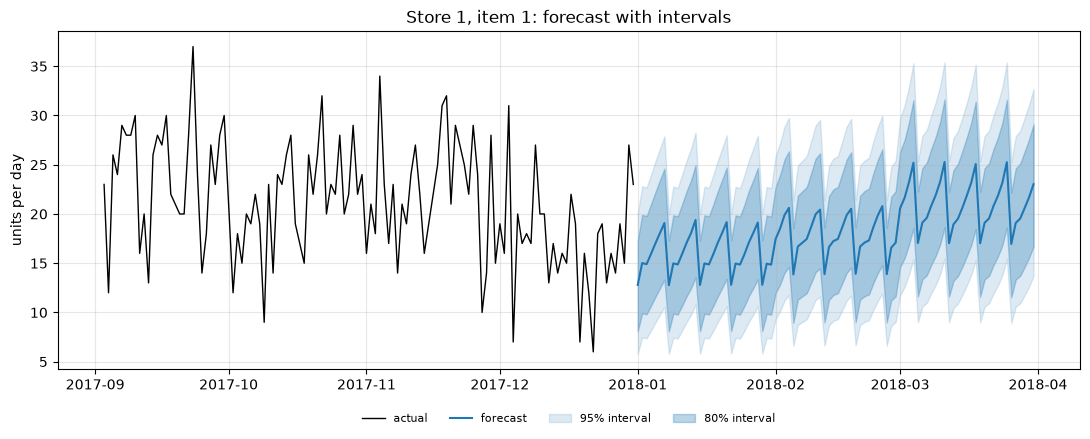

In [9]:
if HAS_BUNDLE:
    store, item = 1, 1
    history = series_slice(bundle.history, store, item)
    forecast = series_slice(bundle.forecast, store, item)
    fig = plot_series_forecast(history, forecast, f"Store {store}, item {item}: forecast with intervals")
    plt.show()

## 7. Where the model errs

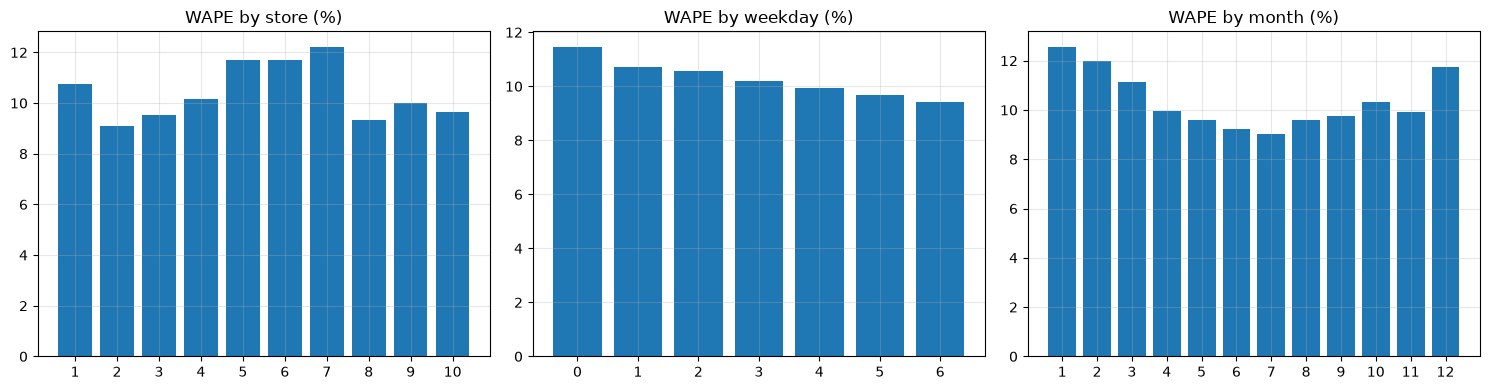

,month,wape,bias
0,1,12.56,3.60
1,2,11.99,2.84
2,3,11.14,3.51
3,4,9.98,-0.19
4,5,9.59,-0.92
5,6,9.24,-0.74
6,7,9.03,-0.02
7,8,9.59,0.09
8,9,9.76,0.78
9,10,10.34,-0.24


In [10]:
if HAS_BUNDLE:
    by_store = backtest_errors(bundle.backtest, "store")
    by_weekday = backtest_errors(bundle.backtest, "weekday")
    by_month = backtest_errors(bundle.backtest, "month")
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, frame, key in zip(axes, (by_store, by_weekday, by_month), ("store", "weekday", "month")):
        ax.bar(frame[key].astype(str), frame["wape"], color="tab:blue")
        ax.set_title(f"WAPE by {key} (%)")
    plt.tight_layout()
    plt.show()
    display(by_month.round(2))

Accuracy depends on **product size, not on the model**: the smallest series score about 22% WAPE and the largest
about 7%, which is what random day-to-day variation alone produces (Spearman correlation between volume and WAPE is
about -0.98). January to March is the weak quarter: the model over-forecasts by about 3% there because sales growth
slowed in 2017.

## 8. Inventory impact

The forecast feeds a periodic-review policy (order every 7 days, lead time 7 days, safety stock from the
forecast's own error distribution). The simulation compares the model with the benchmark and the best baseline on
three held-out quarters of 2017. **Costs here are placeholders and must be replaced with real ones.**

In [11]:
if HAS_BUNDLE:
    business = bundle.summaries["business"]
    print("assumptions:", business["assumptions"])
    at_target = pd.Series(business["inventory_at_target_fill_rate"], name="average inventory (units)")
    display(at_target.to_frame().round(1))
    print("inventory saving at the target fill rate (%):", business["inventory_saving_pct_at_target"])
    print("cost saving at each method's best service level (%):", business["cost_saving_pct_at_optimum"])
    print()
    print("Series that need the biggest safety buffer for the first order:")
    display(at_risk_table(bundle.plan, top=10).round(1))

assumptions: {'lead_time_days': 7, 'review_days': 7, 'holding_cost_per_unit_day': 0.02, 'stockout_cost_per_unit': 3.0, 'target_fill_rate': 0.995, 'target_fill_rate_used': 0.995, 'windows_simulated': [1, 2, 3]}


,average inventory (units)
seasonal_naive_364,277.3
month_weekday_profile_multi_year,269.7
selected_model,261.1


inventory saving at the target fill rate (%): {'vs_benchmark': 5.82, 'vs_best_baseline': 3.17}
cost saving at each method's best service level (%): {'vs_benchmark': 6.63, 'vs_best_baseline': 4.22}

Series that need the biggest safety buffer for the first order:


,store,item,forecast_units,safety_stock,order_up_to,buffer_pct
0,7,5,149.0,25.5,174.4,17.1
1,5,5,161.8,26.5,188.3,16.4
2,6,5,161.9,26.6,188.5,16.4
3,7,27,173.4,27.5,200.9,15.8
4,7,41,175.2,27.6,202.8,15.8
5,7,1,176.1,27.7,203.8,15.7
6,7,4,176.3,27.7,204.0,15.7
7,7,47,176.3,27.7,204.1,15.7
8,6,41,187.7,28.6,216.3,15.2
9,6,47,188.6,28.7,217.2,15.2


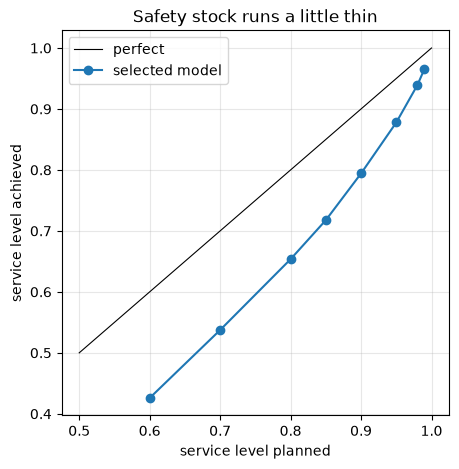

In [12]:
if HAS_BUNDLE:
    coverage = business["coverage_check"]["selected_model"]
    nominal = [row["target"] for row in coverage]
    achieved = [row["achieved"] for row in coverage]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0.5, 1], [0.5, 1], color="black", linewidth=0.8, label="perfect")
    ax.plot(nominal, achieved, marker="o", color="tab:blue", label="selected model")
    ax.set_xlabel("service level planned")
    ax.set_ylabel("service level achieved")
    ax.set_title("Safety stock runs a little thin")
    ax.legend()
    plt.show()

## Conclusions

1. **Accuracy.** The final model's mean WAPE is about 10.4%, against 11.0% for the best simple method and 14.7% for
   the benchmark, a gain of about 30% over the benchmark that holds in every window and for every one of the 500 series.
2. **Why more modelling will not help much.** Error follows product volume, and the model is within about a point of
   the noise floor.
3. **Inventory.** About 6% less stock than the benchmark at the same service level, or about 3% less than the best
   simple method. The money figures depend on placeholder costs.
4. **Caveats.** The planned service level runs a few points lower than its label (see the chart above). This data is
   unusually regular, with no promotions, prices or holidays, so a real retailer should expect noisier results.
5. **Operations.** `scripts/monthly_refresh.ps1` retrains on the newest data and checks the last forecast against
   actual sales. See `docs/operations.md`.